# 06 — Plot rollout results (dynamic_dt)

Reads `rollout_results.json` for **all dt from 3d to 30d** (original 8 + mid-range 23/25/27/30), saves per-run speed-RMSE plots, then builds cross-dt comparison in `Test&Rollout/_comparison/`.

| dt (days) | hours |
|-----------|-------|
| 3,5,7,10,12,15,17,20 | original sweep |
| 23,25,27,30 | mid-range batch |

Run [`05_evaluate_rollout_dynamic_dt.ipynb`](05_evaluate_rollout_dynamic_dt.ipynb) first (both batches if comparing full range).

In [1]:
import sys
from pathlib import Path

NOTEBOOK_DIR = Path.cwd().resolve()
MW_DIR = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "dynamic_dt" else (
    NOTEBOOK_DIR if NOTEBOOK_DIR.name == "Magic_window" else NOTEBOOK_DIR / "Magic_window"
)
DT_DIR = MW_DIR / "dynamic_dt"
ROOT = MW_DIR.parent
for _p in (ROOT, MW_DIR):
    if str(_p) not in sys.path:
        sys.path.insert(0, str(_p))

import importlib
import dynamic_dt.rollout_metrics_plots as _rmp
importlib.reload(_rmp)
from dynamic_dt.rollout_metrics_plots import (
    comparison_output_dir,
    discover_rollout_results,
    metrics_to_long_df,
    load_rollout_results,
    plot_all_rollout_results,
    run_comparison,
    summary_table,
)

from IPython.display import Image, display
import json
import pandas as pd

# Explicit dt list (days) to plot/compare
# Requested: 3,5,7,10,12,15,17,20 plus mid-range: 23,25,27,30
COMPARE_DT_DAYS = [3, 5, 7, 10, 12, 15, 17, 20, 23, 25, 27, 30]

paths = discover_rollout_results(DT_DIR, dt_days_list=COMPARE_DT_DAYS)
print(f"Found {len(paths)} rollout_results.json (dt=3…30, {len(COMPARE_DT_DAYS)} slots)")
for p in sorted(paths, key=lambda x: json.loads(x.read_text())["dt_days"]):
    dt_days = json.loads(p.read_text())["dt_days"]
    print(f"  dt={dt_days:2d}d → {p.parent.name}")
missing = sorted(set(COMPARE_DT_DAYS) - {json.loads(p.read_text())["dt_days"] for p in paths})
if missing:
    print(f"Missing rollout for dt (days): {missing}")

Found 12 rollout_results.json (dt=3…30, 12 slots)
  dt= 3d → adv_no_uv_13_22_magicwin_reference_dt72_vgg_warm10_adv60_wd1e-3
  dt= 5d → adv_no_uv_13_22_magicwin_reference_dt120_vgg_warm10_adv60_wd1e-3
  dt= 7d → adv_no_uv_13_22_magicwin_reference_dt168_vgg_warm10_adv60_wd1e-3
  dt=10d → adv_no_uv_13_22_magicwin_reference_dt240_vgg_warm10_adv60_wd1e-3
  dt=12d → adv_no_uv_13_22_magicwin_reference_dt288_vgg_warm10_adv60_wd1e-3
  dt=15d → adv_no_uv_13_22_magicwin_reference_dt360_vgg_warm10_adv60_wd1e-3
  dt=17d → adv_no_uv_13_22_magicwin_reference_dt408_vgg_warm10_adv60_wd1e-3
  dt=20d → adv_no_uv_13_22_magicwin_reference_dt480_vgg_warm10_adv60_wd1e-3
  dt=23d → adv_no_uv_13_22_magicwin_reference_dt552_vgg_warm10_adv60_wd1e-3
  dt=25d → adv_no_uv_13_22_magicwin_reference_dt600_vgg_warm10_adv60_wd1e-3
  dt=27d → adv_no_uv_13_22_magicwin_reference_dt648_vgg_warm10_adv60_wd1e-3
  dt=30d → adv_no_uv_13_22_magicwin_reference_dt720_vgg_warm10_adv60_wd1e-3


## Per-run plots

Writes into each run folder:
- `speed_rmse_center_and_full.png`
- `speed_rmse_by_horizon_center_and_full.png`
- `speed_rmse_curves_center_and_full.png`

In [2]:
per_run = plot_all_rollout_results(DT_DIR, dt_days_list=COMPARE_DT_DAYS)
print(f"Plotted {len(per_run)} run(s)")
for i, plots in enumerate(per_run):
    run_dir = Path(next(iter(plots.values()))).parent
    print(f"\n{run_dir.name}")
    for name, path in plots.items():
        print(f"  {name}: {path}")

Plotted 12 run(s)

adv_no_uv_13_22_magicwin_reference_dt120_vgg_warm10_adv60_wd1e-3
  center_and_full: /opt/dlami/nvme/tmp_storage/LCADAME/hamid_copy/Magic_window/dynamic_dt/Test&Rollout/adv_no_uv_13_22_magicwin_reference_dt120_vgg_warm10_adv60_wd1e-3/speed_rmse_center_and_full.png
  by_horizon: /opt/dlami/nvme/tmp_storage/LCADAME/hamid_copy/Magic_window/dynamic_dt/Test&Rollout/adv_no_uv_13_22_magicwin_reference_dt120_vgg_warm10_adv60_wd1e-3/speed_rmse_by_horizon_center_and_full.png
  curves: /opt/dlami/nvme/tmp_storage/LCADAME/hamid_copy/Magic_window/dynamic_dt/Test&Rollout/adv_no_uv_13_22_magicwin_reference_dt120_vgg_warm10_adv60_wd1e-3/speed_rmse_curves_center_and_full.png

adv_no_uv_13_22_magicwin_reference_dt168_vgg_warm10_adv60_wd1e-3
  center_and_full: /opt/dlami/nvme/tmp_storage/LCADAME/hamid_copy/Magic_window/dynamic_dt/Test&Rollout/adv_no_uv_13_22_magicwin_reference_dt168_vgg_warm10_adv60_wd1e-3/speed_rmse_center_and_full.png
  by_horizon: /opt/dlami/nvme/tmp_storage/LCADAME/

## Cross-dt comparison

Tables + comparison plots → `Test&Rollout/_comparison/`

In [3]:
info = run_comparison(DT_DIR, dt_days_list=COMPARE_DT_DAYS)
OUT_DIR = Path(info["output_dir"])
print(f"Compared {info['n_runs']} dt runs → {OUT_DIR}")
for label, path in {**info['tables'], **info['plots']}.items():
    print(f"  {label}: {path}")

Compared 12 dt runs → /opt/dlami/nvme/tmp_storage/LCADAME/hamid_copy/Magic_window/dynamic_dt/Test&Rollout/_comparison
  long_csv: /opt/dlami/nvme/tmp_storage/LCADAME/hamid_copy/Magic_window/dynamic_dt/Test&Rollout/_comparison/rollout_metrics_long.csv
  summary_csv: /opt/dlami/nvme/tmp_storage/LCADAME/hamid_copy/Magic_window/dynamic_dt/Test&Rollout/_comparison/rollout_summary.csv
  summary_md: /opt/dlami/nvme/tmp_storage/LCADAME/hamid_copy/Magic_window/dynamic_dt/Test&Rollout/_comparison/rollout_summary.md
  grouped_rmse_bars: /opt/dlami/nvme/tmp_storage/LCADAME/hamid_copy/Magic_window/dynamic_dt/Test&Rollout/_comparison/compare_grouped_rmse_bars.png
  rmse_curves: /opt/dlami/nvme/tmp_storage/LCADAME/hamid_copy/Magic_window/dynamic_dt/Test&Rollout/_comparison/compare_rmse_curves.png
  skill_heatmap: /opt/dlami/nvme/tmp_storage/LCADAME/hamid_copy/Magic_window/dynamic_dt/Test&Rollout/_comparison/compare_skill_heatmap.png
  model_rmse_heatmap: /opt/dlami/nvme/tmp_storage/LCADAME/hamid_copy

## Summary table

In [4]:
long_df = metrics_to_long_df(load_rollout_results(paths))
summary_df = summary_table(long_df)
display(summary_df)

,dt_days,dt_hours,run_name,n_test,persistence_rmse_full_step1,model_rmse_full_step1,skill_score_full_step1,horizon_days_step1,persistence_rmse_full_step2,model_rmse_full_step2,skill_score_full_step2,horizon_days_step2,persistence_rmse_full_step3,model_rmse_full_step3,skill_score_full_step3,horizon_days_step3
0,3,72,adv_no_uv_13_22_magicwin_reference_dt72_vgg_wa...,349,0.156547,0.118557,0.242674,3,0.272700,0.245253,0.100648,6,0.281452,0.245956,0.126118,9
1,5,120,adv_no_uv_13_22_magicwin_reference_dt120_vgg_w...,339,0.200019,0.146302,0.268560,5,0.284931,0.240231,0.156878,10,0.297126,0.239303,0.194608,15
2,7,168,adv_no_uv_13_22_magicwin_reference_dt168_vgg_w...,329,0.222181,0.165449,0.255339,7,0.293607,0.239690,0.183637,14,0.302776,0.234335,0.226045,21
3,10,240,adv_no_uv_13_22_magicwin_reference_dt240_vgg_w...,314,0.248948,0.180515,0.274888,10,0.299600,0.230292,0.231337,20,0.295837,0.226331,0.234948,30
4,12,288,adv_no_uv_13_22_magicwin_reference_dt288_vgg_w...,304,0.265504,0.197513,0.256084,12,0.300788,0.225826,0.249217,24,0.287665,0.229133,0.203472,36
5,15,360,adv_no_uv_13_22_magicwin_reference_dt360_vgg_w...,289,0.282179,0.209498,0.257573,15,0.293880,0.225053,0.234199,30,0.289345,0.232227,0.197404,45
6,17,408,adv_no_uv_13_22_magicwin_reference_dt408_vgg_w...,279,0.287758,0.211591,0.264692,17,0.291436,0.223573,0.232856,34,0.293816,0.235939,0.196983,51
7,20,480,adv_no_uv_13_22_magicwin_reference_dt480_vgg_w...,264,0.295806,0.216764,0.267210,20,0.290458,0.226422,0.220465,40,0.291971,0.239738,0.178900,60
8,23,552,adv_no_uv_13_22_magicwin_reference_dt552_vgg_w...,249,0.298648,0.221763,0.257446,23,0.293266,0.225021,0.232705,46,0.298660,0.226358,0.242088,69
9,25,600,adv_no_uv_13_22_magicwin_reference_dt600_vgg_w...,239,0.299919,0.224329,0.252036,25,0.288089,0.226005,0.215503,50,0.305432,0.217770,0.287010,75


## Comparison figures

compare_grouped_rmse_bars.png


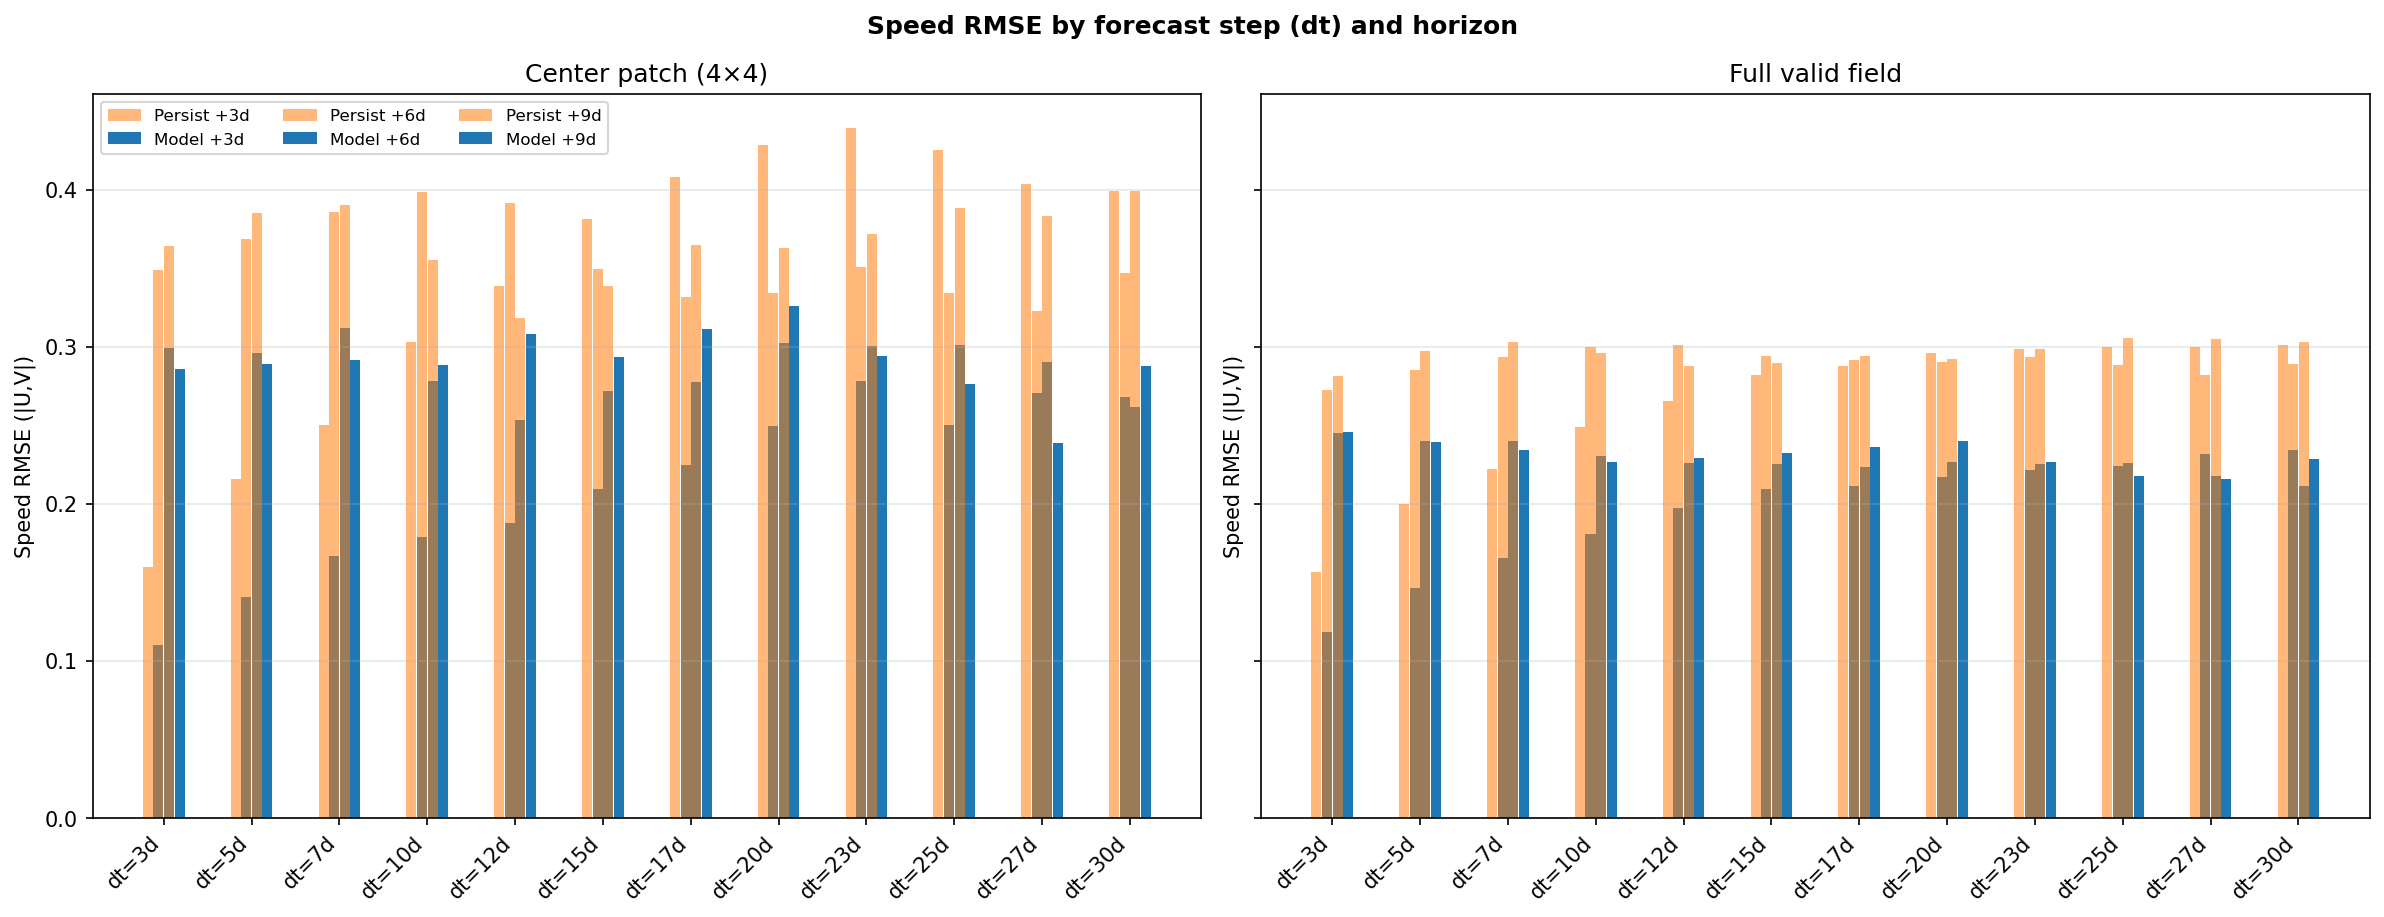

compare_rmse_curves.png


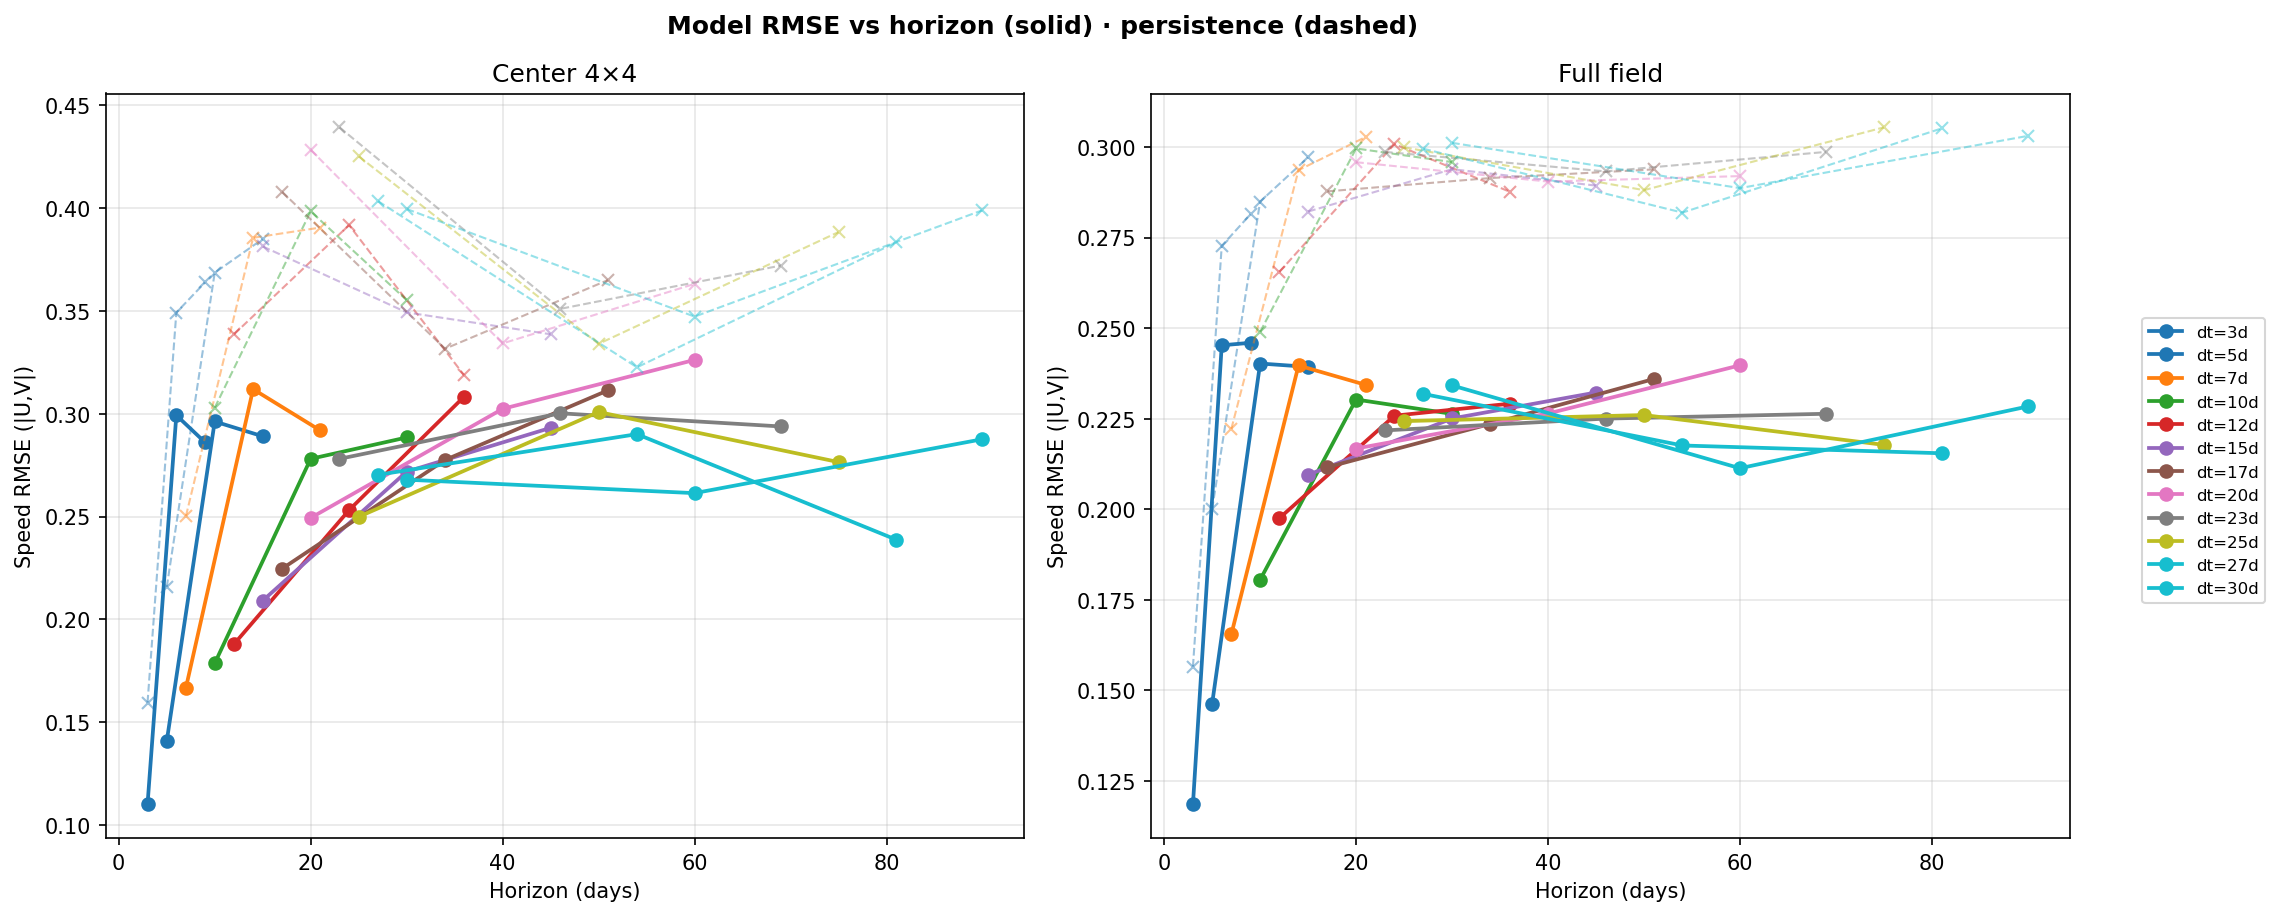

compare_skill_heatmap.png


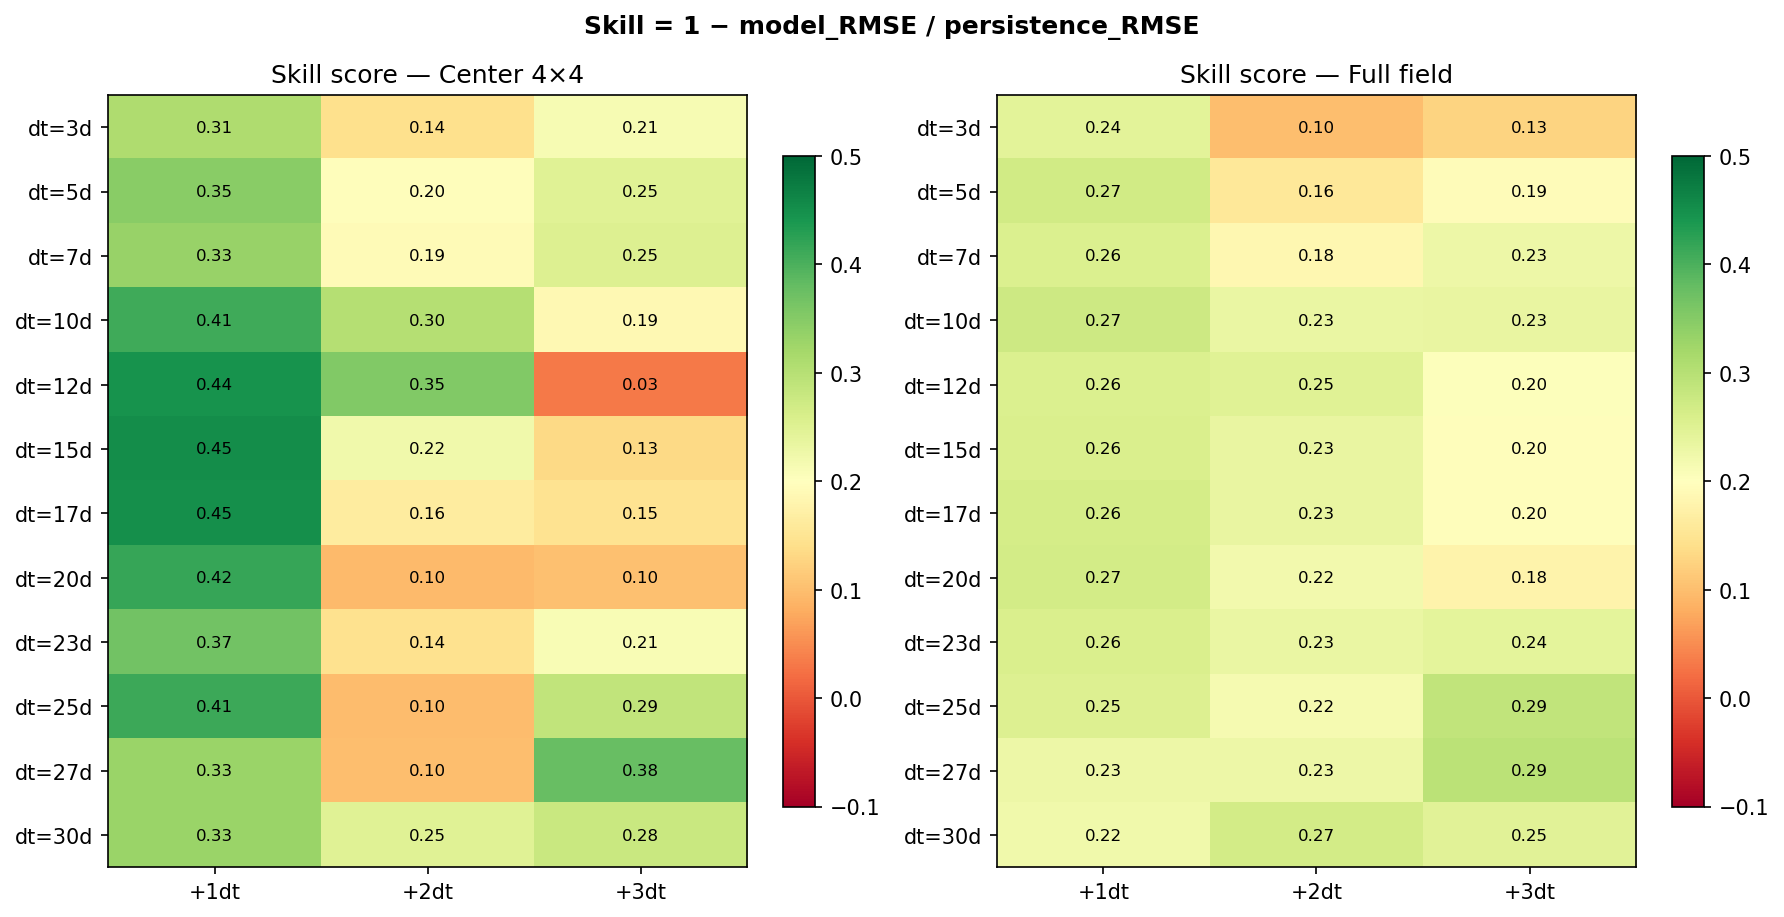

compare_model_rmse_heatmap.png


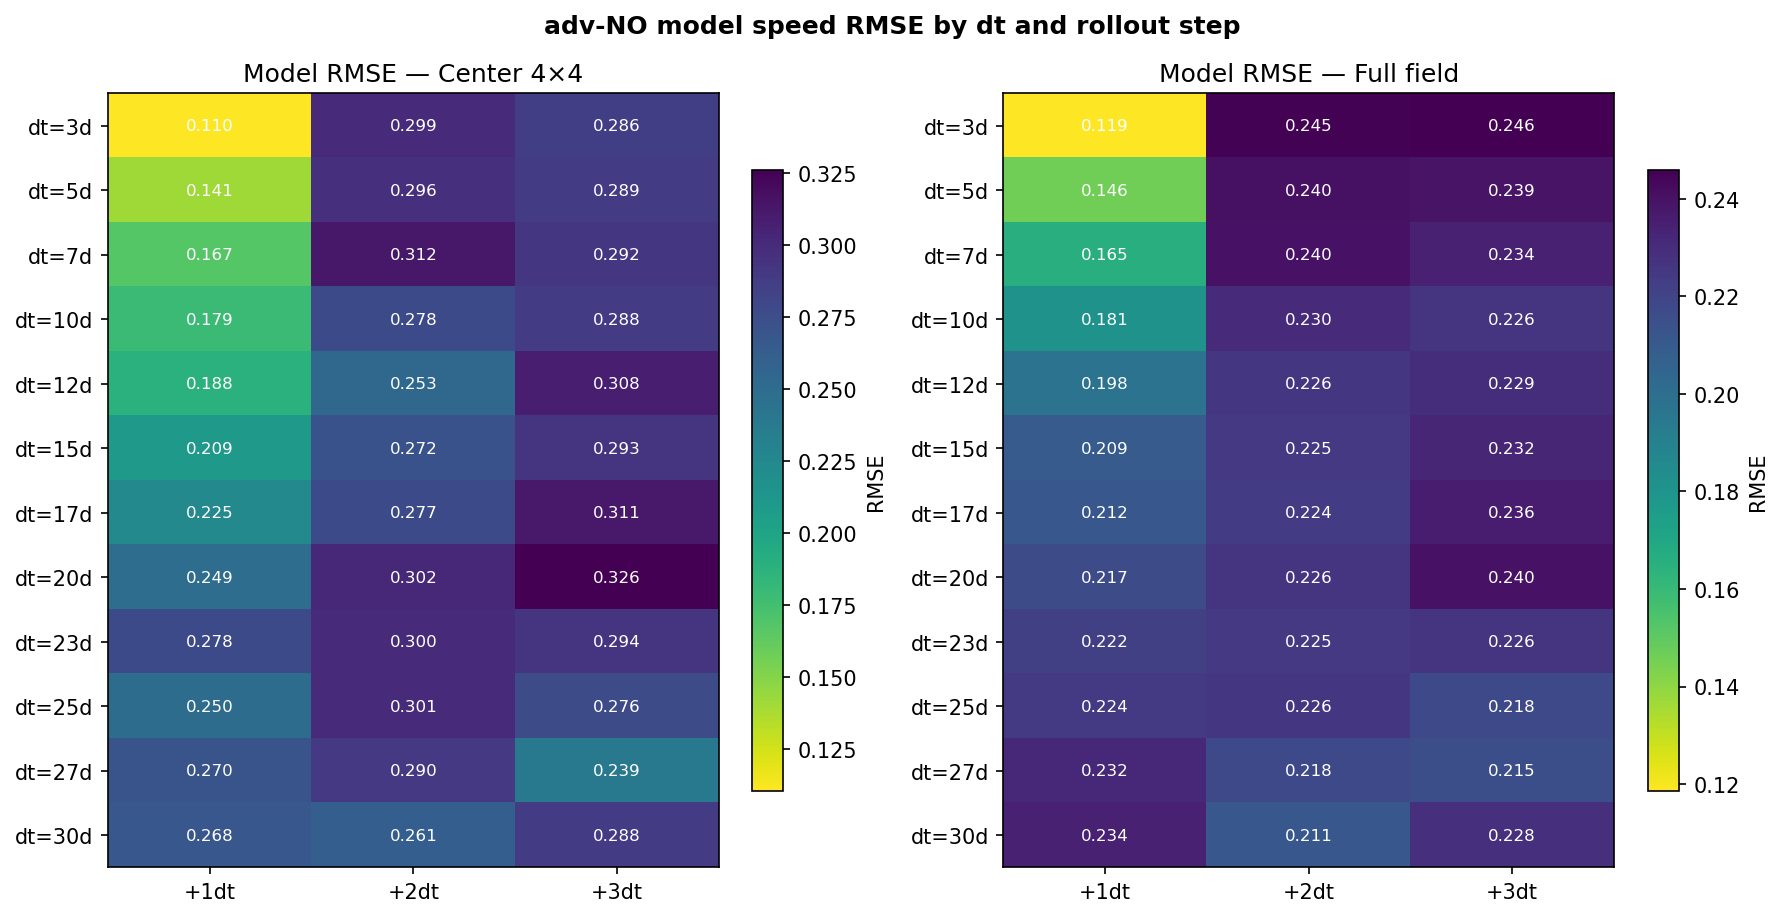

compare_horizon_facets_full.png


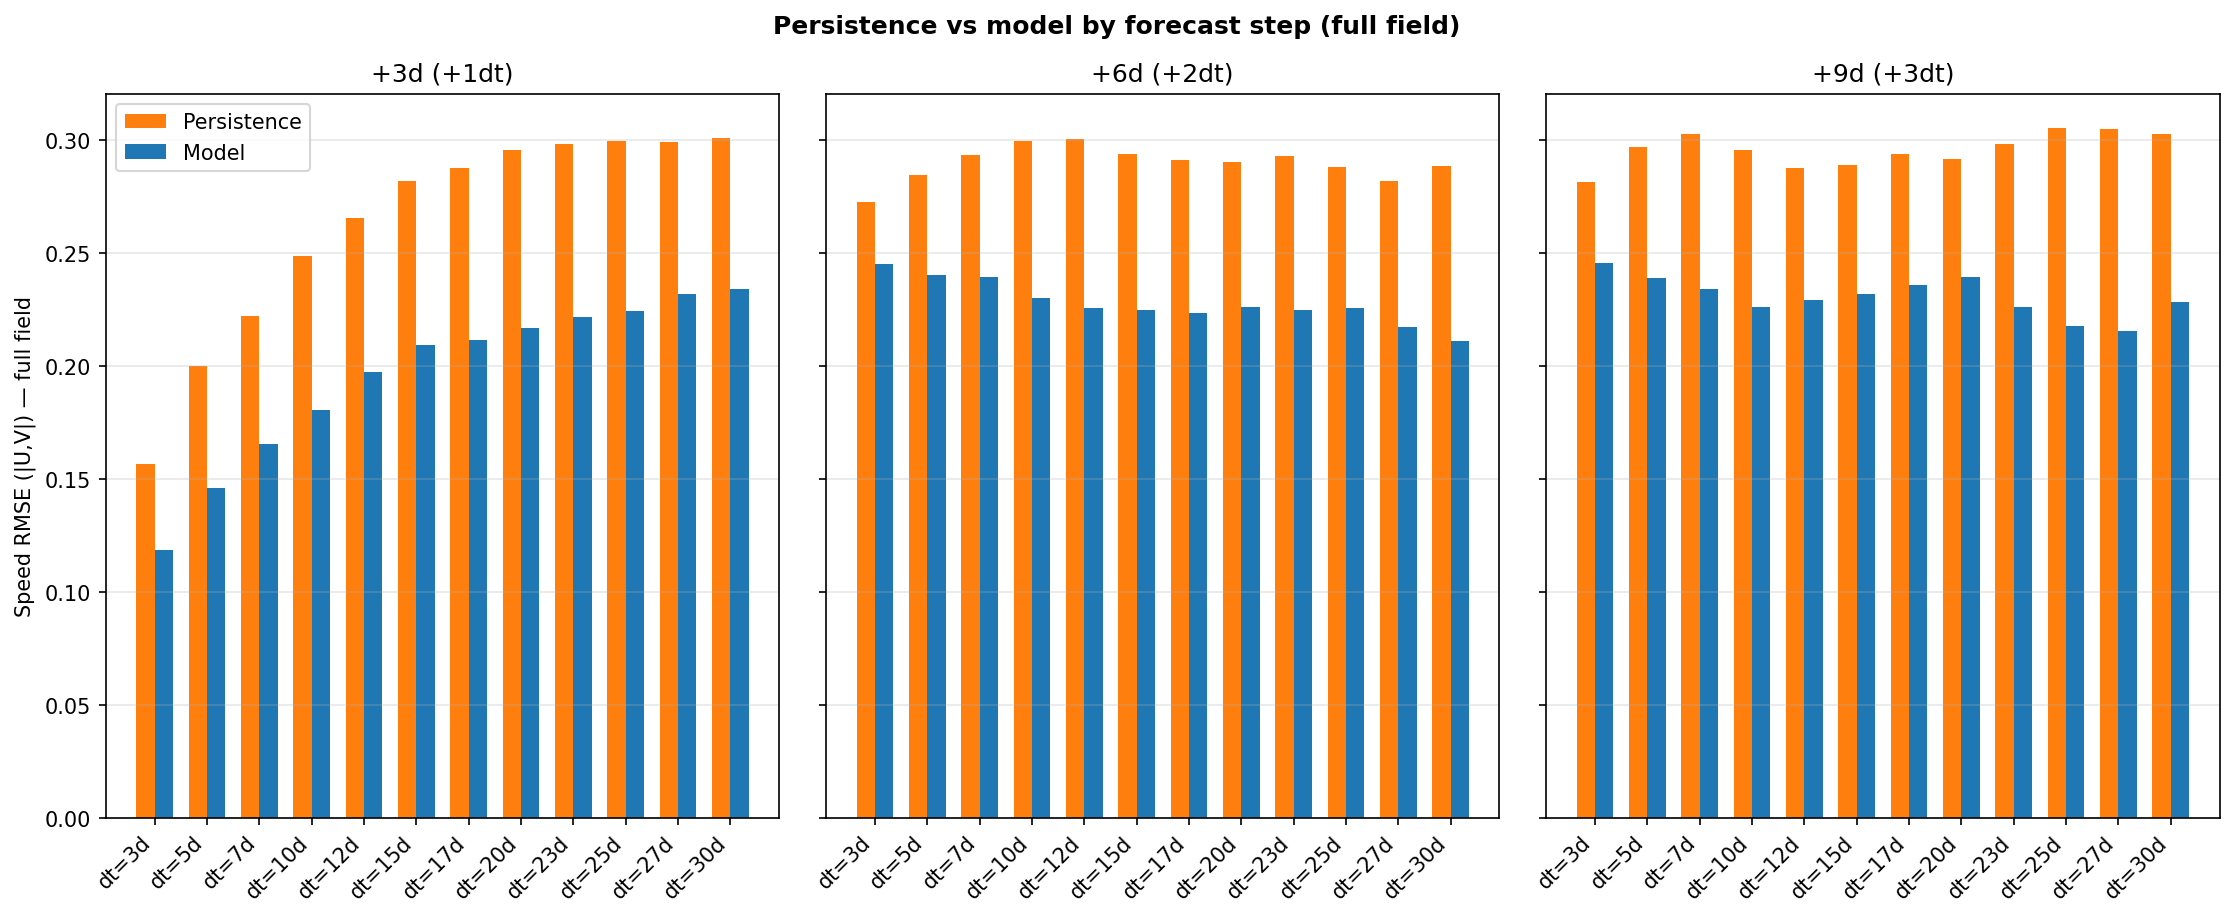

In [5]:
for name in (
    "compare_grouped_rmse_bars.png",
    "compare_rmse_curves.png",
    "compare_skill_heatmap.png",
    "compare_model_rmse_heatmap.png",
    "compare_horizon_facets_full.png",
):
    p = OUT_DIR / name
    if p.is_file():
        print(name)
        display(Image(filename=str(p)))

## Preview one per-run figure (dt=15d / dt360 if present)

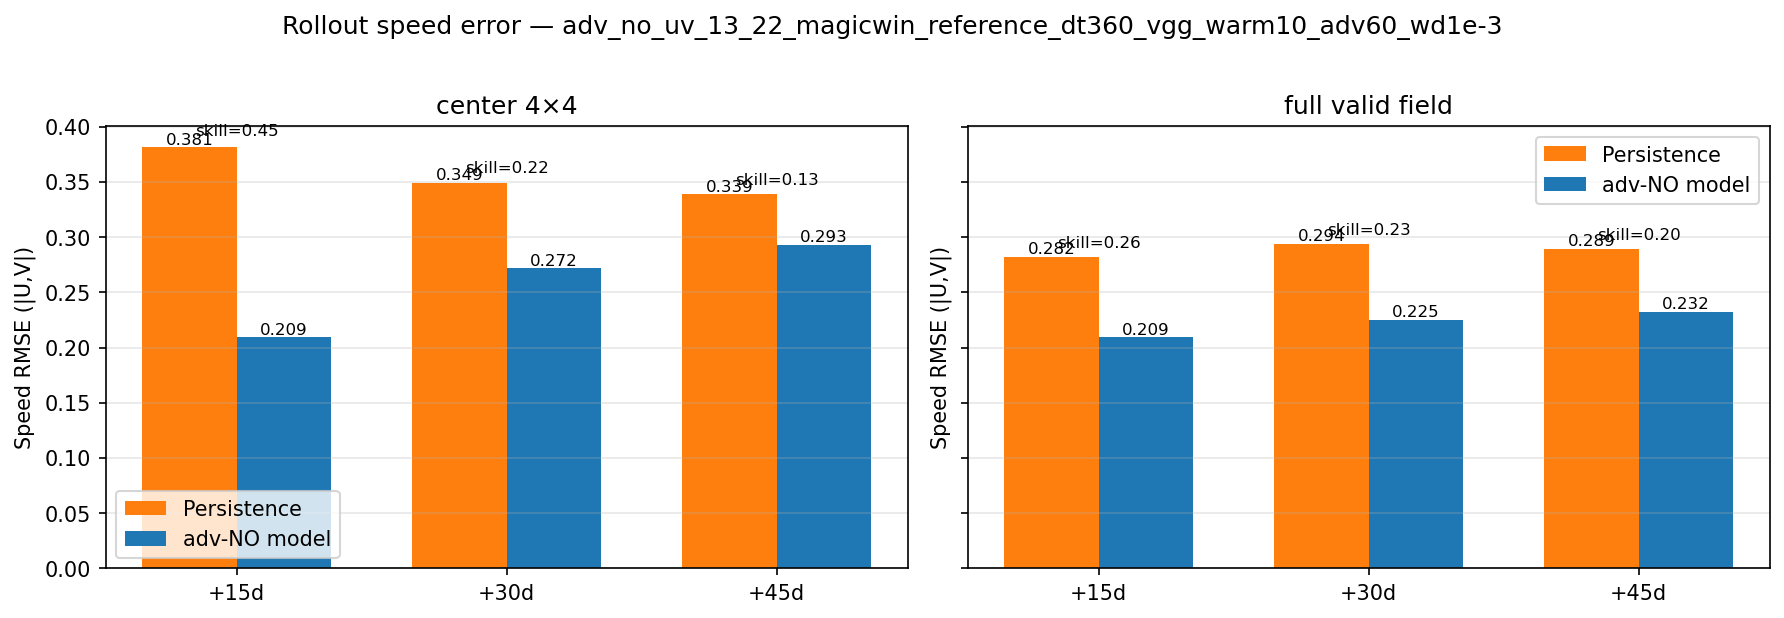

In [6]:
preview = None
for p in paths:
    if "_dt360_" in p.parent.name:
        preview = p.parent / "speed_rmse_center_and_full.png"
        break
if preview is None and paths:
    preview = paths[0].parent / "speed_rmse_center_and_full.png"
if preview and preview.is_file():
    display(Image(filename=str(preview)))
else:
    print("Run the per-run plotting cell above first.")